<a href="https://colab.research.google.com/github/ambre-bissi/ESG-Portfolio-Optimizer/blob/main/Notebooks/1_data_quality.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ESG Data Quality Analysis

**"Puis-je faire confiance à mes données ESG avant de construire un portefeuille ?"**



Objectif :


*   Vérifier la qualité des données ESG
*   Identifier les valeurs manquantes


*   Détecter les anomalies
*   Evaluer la couverture du dataset


In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import zscore

esg = pd.read_csv("data_esg.csv")
esg.head()

,ticker,name,currency,exchange,industry,logo,weburl,environment_grade,environment_level,social_grade,...,governance_grade,governance_level,environment_score,social_score,governance_score,total_score,last_processing_date,total_grade,total_level,cik
0,dis,Walt Disney Co,USD,"NEW YORK STOCK EXCHANGE, INC.",Media,https://static.finnhub.io/logo/ef50b4a2b263c84...,https://thewaltdisneycompany.com/,A,High,BB,...,BB,Medium,510,316,321,1147,19-04-2022,BBB,High,1744489
1,gm,General Motors Co,USD,"NEW YORK STOCK EXCHANGE, INC.",Automobiles,https://static.finnhub.io/logo/9253db78-80c9-1...,https://www.gm.com/,A,High,BB,...,B,Medium,510,303,255,1068,17-04-2022,BBB,High,1467858
2,gww,WW Grainger Inc,USD,"NEW YORK STOCK EXCHANGE, INC.",Trading Companies and Distributors,https://static.finnhub.io/logo/f153dcda-80eb-1...,https://www.grainger.com/,B,Medium,BB,...,B,Medium,255,385,240,880,19-04-2022,BB,Medium,277135
3,mhk,Mohawk Industries Inc,USD,"NEW YORK STOCK EXCHANGE, INC.",Consumer products,https://static.finnhub.io/logo/26868a62-80ec-1...,https://mohawkind.com/,A,High,B,...,BB,Medium,570,298,303,1171,18-04-2022,BBB,High,851968
4,lyv,Live Nation Entertainment Inc,USD,"NEW YORK STOCK EXCHANGE, INC.",Media,https://static.finnhub.io/logo/1cd144d2-80ec-1...,https://www.livenationentertainment.com/,BBB,High,BB,...,B,Medium,492,310,250,1052,18-04-2022,BBB,High,1335258


In [3]:
esg.describe()

,environment_score,social_score,governance_score,total_score,cik
count,722.000000,722.000000,722.000000,722.000000,7.220000e+02
mean,404.806094,292.182825,278.761773,975.750693,9.897925e+05
std,145.103870,57.017406,47.031536,218.751796,5.816815e+05
min,200.000000,160.000000,75.000000,600.000000,1.800000e+03
25%,240.000000,243.000000,235.000000,763.000000,7.231572e+05
50%,483.000000,302.000000,300.000000,1046.000000,1.046189e+06
75%,518.750000,322.750000,310.000000,1144.000000,1.470094e+06
max,719.000000,667.000000,475.000000,1536.000000,1.914023e+06


In [4]:
#répartition des différents types d'industry
#esg["industry"].value_counts(normalize=False)

#esg["industry"].nunique()



*   Combien d'entreprises possède-t-on ?

-> 722

*   Combien de secteurs ?

-> 47

*   Combien de variables ESG ?

-> des colonnes "grades" et "level" pour chaque score, inutiles pour le moment donc supprimées

*   Les scores sont plausibles ? (entre 0 et 100 normalement)

->entre 0 et 1000 ici, donc ajuster en divisant par 10 si important

et total_score est la somme des 3scores, donc entre 0 et 3000

In [5]:
#controle des doublons

esg.duplicated().sum() #pas de doublons ici

#si doublons :
#esg[esg.duplicated()]

#esg = esg.drop_duplicates()

np.int64(0)

In [6]:
#analyse des valeurs manquantes

coverage = (esg.notna().mean()*100)
print(coverage)

ticker                  100.000000
name                    100.000000
currency                100.000000
exchange                100.000000
industry                 98.199446
logo                     97.229917
weburl                   97.783934
environment_grade       100.000000
environment_level       100.000000
social_grade            100.000000
social_level            100.000000
governance_grade        100.000000
governance_level        100.000000
environment_score       100.000000
social_score            100.000000
governance_score        100.000000
total_score             100.000000
last_processing_date    100.000000
total_grade             100.000000
total_level             100.000000
cik                     100.000000
dtype: float64


Quels scores sont les moins bien couverts ?

-> tout les scores sont bien couverts

Comment gérer ces absences de valeur ?

-> seul la colonne secteur (industry) est utile et avec des valeurs manquantes, donc assigner "autre" aux valeurs manquantes devrait suffir

In [7]:
#supprésion des colonnes inutiles
esg.drop(columns=["currency", "exchange", "weburl", "environment_grade",	"environment_level",	"social_grade", "social_level", "governance_grade","governance_level", "total_grade", "total_level", "cik"])

#la modification s'effectue sur l'ensemble de la suite du notebook ou juste ici ?
#la modification s'effectue juste ici, ce n'est pas gênant dans ce projet mais il faudra y faire attention

,ticker,name,industry,logo,environment_score,social_score,governance_score,total_score,last_processing_date
0,dis,Walt Disney Co,Media,https://static.finnhub.io/logo/ef50b4a2b263c84...,510,316,321,1147,19-04-2022
1,gm,General Motors Co,Automobiles,https://static.finnhub.io/logo/9253db78-80c9-1...,510,303,255,1068,17-04-2022
2,gww,WW Grainger Inc,Trading Companies and Distributors,https://static.finnhub.io/logo/f153dcda-80eb-1...,255,385,240,880,19-04-2022
3,mhk,Mohawk Industries Inc,Consumer products,https://static.finnhub.io/logo/26868a62-80ec-1...,570,298,303,1171,18-04-2022
4,lyv,Live Nation Entertainment Inc,Media,https://static.finnhub.io/logo/1cd144d2-80ec-1...,492,310,250,1052,18-04-2022
...,...,...,...,...,...,...,...,...,...
717,hi,Hillenbrand Inc,Machinery,https://static.finnhub.io/logo/f56bfd2c-80eb-1...,489,349,300,1138,07-11-2022
718,hhc,Howard Hughes Corp,Real Estate,https://static.finnhub.io/logo/6445e7f28561553...,500,300,300,1100,07-11-2022
719,hubs,HubSpot Inc,Technology,https://static.finnhub.io/logo/62f8c2fa-80d0-1...,480,329,320,1129,07-11-2022
720,hesm,Hess Midstream LP,Energy,https://static.finnhub.io/logo/3a3f1306ad581fe...,307,257,255,819,15-11-2022


<Axes: xlabel='total_score'>

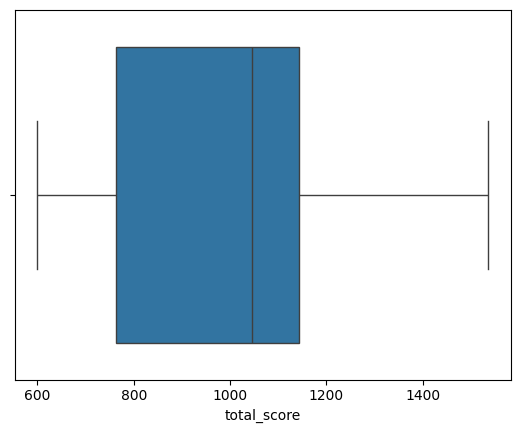

In [8]:
#détection d'anomalies

esg["z_score"] = zscore(esg["total_score"])
#"ESG"<->"total_score"

#outliers = esg[abs(esg["z_score"]) > 3]

sns.boxplot(x=esg["total_score"])

Certaines entreprises ont-elles des scores anormalement élevés ou faibles ?

->pas d'outliers détectées

<Axes: ylabel='industry'>

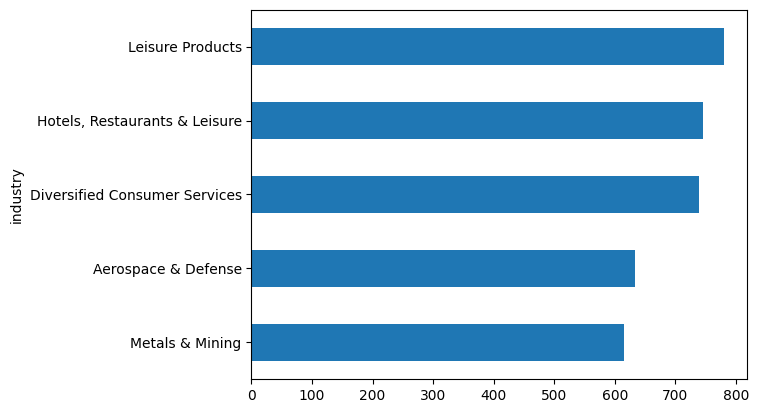

In [9]:
#analyse par secteurs

sector_means = (esg.groupby("industry")["total_score"].mean().sort_values(ascending=True))

sector_means.head(5).plot.barh()

<Axes: ylabel='industry'>

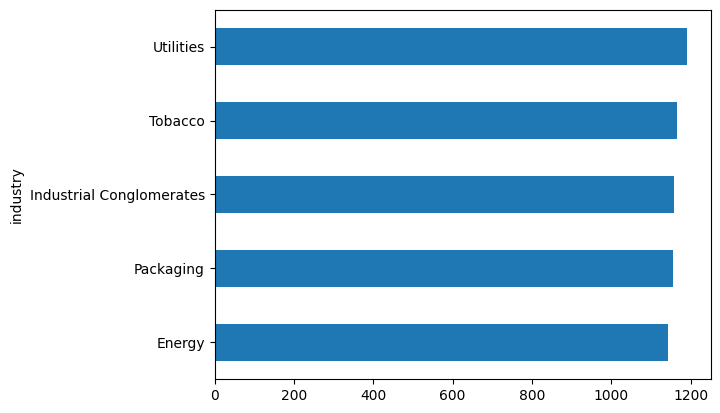

In [10]:
sector_means.tail(5).plot.barh()

"C'était prévisible ?"
-> les derniers (defence et mining) étaient prévisibles

mais tobacco en second est très surprenant

In [15]:
# Filtrer le dataset pour n'obtenir que les entreprises du secteur 'Tobacco'
tobacco_esg = esg[esg["industry"] == "Tobacco"]
display(tobacco_esg[["ticker", "name","industry", "environment_score", "social_score", "governance_score", "total_score"]])

,ticker,name,industry,environment_score,social_score,governance_score,total_score
330,mo,Altria Group Inc,Tobacco,500,327,341,1168
358,pm,Philip Morris International Inc,Tobacco,520,327,315,1162


Le score élévé de Tobacco s'explique par son bon score environnement, cependant je ne comprend pas comment le social_score peut être aussi peu bas, sachant que le tabac détruit des vies. La façon dont les scores sont calculés devra être étudiée pour comprendre ceci.

# yfinance Data Quality Analysis

In [13]:
import yfinance as yf

tickers = esg["ticker"]

prices = yf.download(tickers.tolist(), start="2021-01-01", end="2026-01-01", auto_adjust=True)["Close"]

[*********************100%***********************]  722 of 722 completed
ERROR:yfinance:
130 Failed downloads:
ERROR:yfinance:['CTXS', 'PKI', 'AGIL', 'USAK', 'HEP', 'SIEN', 'AGFS', 'AHPI', 'AGLE', 'NLSN', 'HHC', 'WWE', 'CLXT', 'ZEN', 'ACRX', 'DISH', 'ZUO', 'PXD', 'AIKI', 'FLT', 'X', 'AKUS', 'PPBI', 'AKIC', 'MTEM', 'PLYA', 'HALL', 'ATVI', 'ACEV', 'HES', 'ADOC', 'ACAC', 'GPS', 'ABMD', 'HAPP', 'PNT', 'ADES', 'HCCI', 'AKRO', 'ALBO', 'ACOR', 'HAAC', 'XIN', 'UTME', 'AGRX', 'HOLX', 'ADVM', 'MMC', 'AGFY', 'AIH', 'ZEV', 'AESE', 'WBA', 'HCAR', 'CDAY', 'FRC', 'XL', 'AERI', 'ADMP', 'CLSN', 'ALLK', 'NLOK', 'ANSS', 'PEAK', 'USAP', 'AGTC', 'FBHS', 'HARP', 'HA', 'MTCR', 'DRE', 'SHYF', 'RE', 'ACER', 'AIMC', 'AFMD', 'CTLT', 'TRTN', 'AAWW', 'MRO', 'ACCD', 'SIVB', 'MYMD', 'Y', 'DFS', 'WRK', 'ABTX', 'HCDI', 'ALIM', 'EVK', 'AFAQ', 'ABIO', 'AKYA', 'AKU', 'HAYN', 'AEY', 'AADI', 'ABC', 'GVP', 'CND', 'ACHL', 'MTTR', 'CLVS']: YFTzMissingError('possibly delisted; no timezone found')
ERROR:yfinance:['EA', 'ADIL', 

In [19]:
prices.head()

Ticker,A,AACG,AACI,AADI,AAL,AAME,AAOI,AAON,AAP,AAPL,...,ZBRA,ZEN,ZEPP,ZEV,ZIM,ZION,ZTS,ZUO,ZWS,ZYME
Date,,,,,,,,,,,,,,,,,,,,,
2021-01-04,114.009132,1.18,NaN,NaN,15.13,2.043613,8.76,41.937092,137.724915,125.537109,...,378.130005,NaN,49.327869,NaN,NaN,35.169945,152.952011,NaN,17.734859,48.970001
2021-01-05,114.941261,1.23,NaN,NaN,15.43,2.482893,8.91,42.410194,137.576050,127.089264,...,380.570007,NaN,51.571800,NaN,NaN,35.727032,154.017868,NaN,18.243263,50.880001
2021-01-06,118.093239,1.22,NaN,NaN,15.52,2.196406,9.58,44.639576,145.524078,122.811195,...,394.820007,NaN,52.306885,NaN,NaN,39.741295,156.280518,NaN,19.058558,51.669998
2021-01-07,121.235603,1.27,NaN,NaN,15.38,2.253703,9.64,45.670021,146.767059,127.001938,...,409.100006,NaN,51.300983,NaN,NaN,40.953770,156.140274,NaN,20.171568,53.540001
2021-01-08,122.100449,1.24,NaN,NaN,15.13,2.301451,10.19,44.918251,148.859070,128.098099,...,405.470001,NaN,51.610493,NaN,NaN,39.913338,157.178116,NaN,20.354774,56.810001


Les Tickers sont bien les colonnes, et les dates les lignes.

In [17]:
#valeurs manquantes
prices.isna().sum()

#prices.index #les entreprises ont elles les mêmes dates -> oui

,0
Ticker,
A,0
AACG,0
AACI,1255
AADI,1255
AAL,0
...,...
ZION,0
ZTS,0
ZUO,1255


Certains Tickers n'ont pas pu être téléchargés, ce qui était prévisible.

In [25]:
prices[prices.isna()]

prices2 = prices.drop(columns=prices.columns[prices.isna().any()])

prices2.isna().sum()
#prices2.head()

,0
Ticker,
A,0
AACG,0
AAL,0
AAME,0
AAOI,0
...,...
ZEPP,0
ZION,0
ZTS,0


On a maintenant 569 Tickers

In [27]:
#rendements extrêmes
returns = prices2.pct_change() #la variation en pourcentage d'un jour sur l'autre pour chaque action

returns.describe()

Ticker,A,AACG,AAL,AAME,AAOI,AAON,AAP,AAPL,AATC,ABBV,...,YSG,YUM,YUMC,ZBH,ZBRA,ZEPP,ZION,ZTS,ZWS,ZYME
count,1254.000000,1254.000000,1254.000000,1254.000000,1254.000000,1254.000000,1254.000000,1254.000000,1254.000000,1254.000000,...,1254.000000,1254.000000,1254.000000,1254.000000,1254.000000,1254.000000,1254.000000,1254.000000,1254.000000,1254.000000
mean,0.000296,0.007551,0.000466,0.001415,0.003371,0.000817,-0.000509,0.000767,0.001288,0.000874,...,-0.000865,0.000440,0.000175,-0.000234,-0.000046,0.001042,0.000761,-0.000032,0.000975,0.000315
std,0.017942,0.277078,0.030308,0.052984,0.069029,0.026060,0.032281,0.017552,0.035425,0.014137,...,0.055616,0.012710,0.023296,0.016316,0.024647,0.057672,0.027312,0.016738,0.020600,0.040239
min,-0.096645,-0.557343,-0.144784,-0.204280,-0.321759,-0.229171,-0.350357,-0.092456,-0.239611,-0.125664,...,-0.395161,-0.084360,-0.155094,-0.151483,-0.172717,-0.207279,-0.257249,-0.137790,-0.110315,-0.288490
25%,-0.009536,-0.027027,-0.016573,-0.019756,-0.030523,-0.012081,-0.013994,-0.007934,-0.009958,-0.006121,...,-0.030464,-0.006613,-0.011466,-0.008492,-0.012845,-0.028865,-0.012714,-0.008774,-0.010367,-0.020174
50%,0.000387,0.000000,0.000000,0.000000,-0.001603,0.000725,-0.000262,0.001096,0.000000,0.001149,...,0.000000,0.000539,-0.000256,-0.000476,0.000256,-0.003025,0.001261,0.000247,0.000633,0.000000
75%,0.010368,0.022727,0.014872,0.019980,0.032258,0.013401,0.013454,0.009843,0.010958,0.008782,...,0.025502,0.007660,0.011143,0.008187,0.013152,0.021277,0.014568,0.009425,0.011827,0.019786
max,0.087208,9.514706,0.226020,1.175732,0.670713,0.160705,0.570425,0.153288,0.734663,0.063605,...,0.246575,0.097219,0.148468,0.079868,0.141566,0.694581,0.192173,0.070887,0.122028,0.290497


 L'action AACG a fait une pointe à +951% en une journée : hausse spectaculaire ou anomalie ? -> la médiane (50%) reste à 0 et la moyenne reste plausible donc cela pourrait être une hausse spectaculaire. *(Supposons qu'il n'y a pas d'anomalies pour le moment)*

# Fusion des datasets

In [31]:
# 1. Uniformiser la casse des tickers dans le dataset ESG (en majuscules)
esg["ticker"] = esg["ticker"].str.upper()

# 2. Calculer le rendement moyen et la volatilité pour chaque ticker
stats_rendements = pd.DataFrame({
    "ticker": returns.mean().index.str.upper(),  # S'assurer que l'index est aussi en majuscules
    "rendement_moyen": returns.mean().values,
    "volatilite": returns.std().values
})

# 3. Fusionner avec le dataset ESG sur la colonne 'ticker' (en majuscules)
merged = esg.merge(stats_rendements, on="ticker")

print("Nouvelle forme du dataset fusionné :", merged.shape)
merged.head()

Nouvelle forme du dataset fusionné : (569, 24)


,ticker,name,currency,exchange,industry,logo,weburl,environment_grade,environment_level,social_grade,...,social_score,governance_score,total_score,last_processing_date,total_grade,total_level,cik,z_score,rendement_moyen,volatilite
0,DIS,Walt Disney Co,USD,"NEW YORK STOCK EXCHANGE, INC.",Media,https://static.finnhub.io/logo/ef50b4a2b263c84...,https://thewaltdisneycompany.com/,A,High,BB,...,316,321,1147,19-04-2022,BBB,High,1744489,0.783390,-0.000168,0.018357
1,GM,General Motors Co,USD,"NEW YORK STOCK EXCHANGE, INC.",Automobiles,https://static.finnhub.io/logo/9253db78-80c9-1...,https://www.gm.com/,A,High,BB,...,303,255,1068,17-04-2022,BBB,High,1467858,0.422000,0.000858,0.023461
2,GWW,WW Grainger Inc,USD,"NEW YORK STOCK EXCHANGE, INC.",Trading Companies and Distributors,https://static.finnhub.io/logo/f153dcda-80eb-1...,https://www.grainger.com/,B,Medium,BB,...,385,240,880,19-04-2022,BB,Medium,277135,-0.438017,0.000913,0.015409
3,MHK,Mohawk Industries Inc,USD,"NEW YORK STOCK EXCHANGE, INC.",Consumer products,https://static.finnhub.io/logo/26868a62-80ec-1...,https://mohawkind.com/,A,High,B,...,298,303,1171,18-04-2022,BBB,High,851968,0.893180,0.000121,0.024428
4,LYV,Live Nation Entertainment Inc,USD,"NEW YORK STOCK EXCHANGE, INC.",Media,https://static.finnhub.io/logo/1cd144d2-80ec-1...,https://www.livenationentertainment.com/,BBB,High,BB,...,310,250,1052,18-04-2022,BBB,High,1335258,0.348807,0.000810,0.022397


In [32]:
#enregistre merged au format csv
merged.to_csv("merged.csv", index=False)

# Conclusions

Le dataset Kaggle était déjà propre et l'importation via yfinance fait qu'il n'y avait pas beaucoup de préparation à faire pour les données.

La partie qui m'a le plus posée problème était la fusion des datasets.